# EuroSAT — Initial Data Exploration

## Objective

Inspect the EuroSAT RGB dataset before training a classification model.

This notebook answers five questions:

1. How many examples are available?
2. What are the input features?
3. What ranges do the feature values take?
4. What is the prediction target?
5. Are there missing values or unreadable images?

Each example is a satellite image patch. The classification task is to
predict its land-use or land-cover category.

## 1. Install Dependencies

We use NumPy for numerical operations, pandas for summary tables,
Pillow for reading images, and Matplotlib for visualisation.

## 2. Locate the Dataset

We specify the location of the extracted EuroSAT RGB dataset and
search its subfolders for JPEG images.

The dataset remains on the local computer. Images are read directly
from their existing folders.

In [4]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Folder containing the extracted EuroSAT dataset
DATA_DIR = Path(r"/Users/ishika/Documents/EuroSatellite")

assert DATA_DIR.is_dir(), f"Folder not found: {DATA_DIR}"

image_paths = sorted(
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in {".jpg", ".jpeg"}
)

assert image_paths, "No images found. Check the path and extract the ZIP first."

print(f"Number of image files: {len(image_paths):,}")
print(f"First image: {image_paths[0]}")

Number of image files: 27,000
First image: /Users/ishika/Documents/EuroSatellite/EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg


## 3. Number of Examples and Target Classes

We count the total number of image files and the examples in each class.

The target is a categorical label describing the land use or land cover
shown in an image. Labels are obtained from the parent folder names.

Class counts help us assess whether the dataset is balanced or whether
some categories contain more examples than others.

In [5]:
class_counts = Counter(path.parent.name for path in image_paths)

class_table = pd.DataFrame(
    sorted(class_counts.items()),
    columns=["Target class", "Number of examples"]
)

display(class_table)

print(f"Total examples: {len(image_paths):,}")
print(f"Number of target classes: {len(class_counts)}")

,Target class,Number of examples
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


Total examples: 27,000
Number of target classes: 10


## 4. Input Features, Value Ranges and Missing Values

The input features are the image pixels, arranged by height, width
and colour channel. RGB images contain three channels: red, green and blue.

We inspect every image to determine:

- Image dimensions and number of channels.
- Colour mode and pixel data type.
- Observed minimum and maximum pixel values.
- Number of missing pixel values (NaN).
- Number of missing folder-derived target labels.
- Number of files that cannot be read.

A 64 × 64 RGB image contains 12,288 pixel-channel values.
For uint8 images, the possible pixel range is 0–255; we calculate
the actual observed range from the files.

Zero-valued pixels are valid and are not automatically considered missing.
Folder-derived labels do not establish whether each image was labelled
correctly; label correctness requires a separate review.

In [6]:
records = []
unreadable = []

for path in image_paths:
    try:
        with Image.open(path) as image:
            pixels = np.array(image)
            mode = image.mode

        records.append({
            "filename": path.name,
            "target": path.parent.name,
            "shape": pixels.shape,
            "mode": mode,
            "dtype": str(pixels.dtype),
            "pixel_min": int(pixels.min()),
            "pixel_max": int(pixels.max()),
            "missing_pixels": int(np.isnan(pixels).sum())
        })

    except Exception as error:
        unreadable.append({
            "file": str(path),
            "error": str(error)
        })

metadata = pd.DataFrame(records)
assert not metadata.empty, "No images could be read."

print("Image shapes:")
display(metadata["shape"].value_counts())

print("Colour modes:")
display(metadata["mode"].value_counts())

print("Pixel data types:")
display(metadata["dtype"].value_counts())

print(
    "Observed pixel range:",
    metadata["pixel_min"].min(),
    "to",
    metadata["pixel_max"].max()
)

missing_labels = (
    metadata["target"].isna()
    | metadata["target"].str.strip().eq("")
).sum()

print("Missing target labels:", missing_labels)
print("Missing pixel values (NaN):", metadata["missing_pixels"].sum())
print("Unreadable images:", len(unreadable))

if unreadable:
    display(pd.DataFrame(unreadable))

Image shapes:


shape
(64, 64, 3)    27000
Name: count, dtype: int64

Colour modes:


mode
RGB    27000
Name: count, dtype: int64

Pixel data types:


dtype
uint8    27000
Name: count, dtype: int64

Observed pixel range: 0 to 255
Missing target labels: 0
Missing pixel values (NaN): 0
Unreadable images: 0


## 5. Visual Inspection

We display one image from each target class to understand the dataset
visually and check that images load correctly.

This provides an initial view of differences between categories, including
colour, texture and spatial structure. One example per class is only a
preliminary check and cannot establish the quality of the entire dataset.

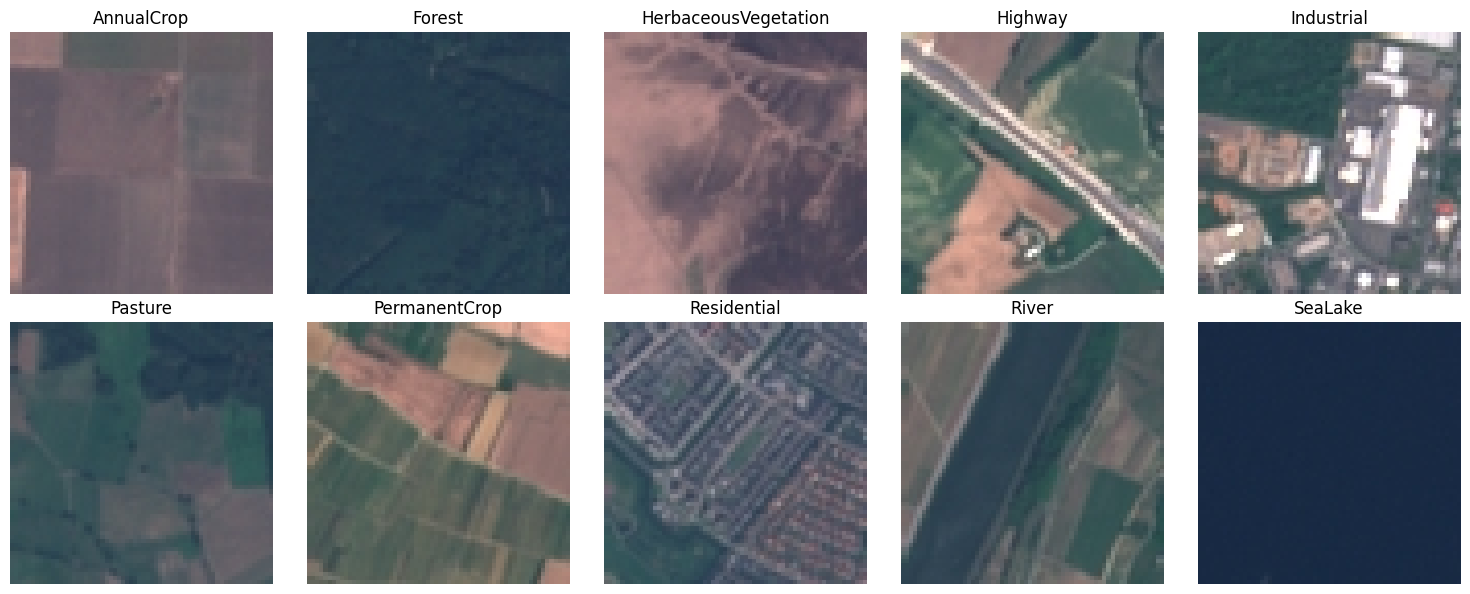

In [7]:
examples = {}

for path in image_paths:
    examples.setdefault(path.parent.name, path)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, (label, path) in zip(axes.flat, sorted(examples.items())):
    try:
        with Image.open(path) as image:
            ax.imshow(image)
        ax.set_title(label)
    except Exception:
        ax.set_title(f"{label}\nUnreadable")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Findings

| Property | Observed result |
|---|---|
| Total examples | 27,000 |
| Successfully read images | 27,000 |
| Target classes | 10 |
| Image dimensions | 64 × 64 pixels |
| Colour channels | 3: red, green and blue |
| Pixel data type | uint8 |
| Observed pixel range | 0–255 |
| Missing pixel values (NaN) | 0 |
| Missing folder-derived labels | 0 |
| Unreadable images | 0 |

### Class Distribution

| Target class | Number of examples |
|---|---:|
| AnnualCrop | 3,000 |
| Forest | 3,000 |
| HerbaceousVegetation | 3,000 |
| Highway | 2,500 |
| Industrial | 2,500 |
| Pasture | 2,000 |
| PermanentCrop | 2,500 |
| Residential | 3,000 |
| River | 2,500 |
| SeaLake | 3,000 |

### Input Features and Target

Each example is a 64 × 64 satellite image with three RGB channels,
giving 12,288 pixel-channel values per image. The pixel values are
stored as unsigned 8-bit integers and range from 0 to 255.

The target is one of 10 land-use or land-cover categories, obtained
from the image's parent folder name. This is a supervised,
single-label, multiclass classification task.

### Class Balance

The dataset has mild class imbalance. Class sizes range from 2,000
to 3,000 images. Pasture is the smallest class, and the largest
classes contain 1.5 times as many examples.

We will use stratified splitting to preserve class proportions
across the training, validation and test sets.

### Data Quality

All 27,000 images were read successfully and have the same shape,
colour mode and data type. No missing pixel values or missing
folder-derived labels were detected.

These checks do not establish whether labels are correct or whether
duplicate images exist. Zero-valued pixels are valid and were not
treated as missing.

### Conclusion

The initial structural checks passed. No missing-value imputation
or removal of unreadable images is required based on these results.